In [1]:
import numpy as np
import random
from IPython.display import clear_output
from matplotlib import pyplot as plt
import gym

import time

In [2]:
entorno = gym.make("Taxi-v3").env
entorno.render()

print('Cantidad de estados: {}'.format(entorno.observation_space.n))
print('Cantidad de acciones: {}'.format(entorno.action_space.n))

+---------+
|R: | : :G|
| : | : : |
| : : : : |
| | : | : |
|Y| : |B: |
+---------+

Cantidad de estados: 500
Cantidad de acciones: 6


In [ ]:
print("El espacio de acción es: ", entorno.action_space)
print("El espacio de observación es: ", entorno.observation_space)

El espacio de acción es:  Discrete(6)
El espacio de observación es:  Discrete(500)


Episodio: 100000
+---------+
|R: | : :G|
| : | : : |
| : : : : |
| | : | : |
|Y| : |B: |
+---------+
  (Dropoff)
**********************************
Entrenamiento Completo!

**********************************


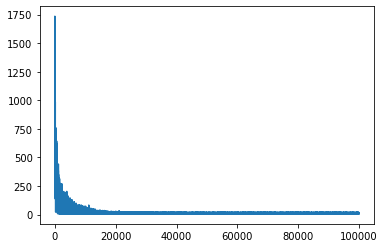

In [3]:
# Q-Learning

alpha = 0.01
gamma = 0.9
epsilon = 0.01
q_table = np.zeros([entorno.observation_space.n, entorno.action_space.n])

estado_anterior = None
mostrar_entrenamiento = False
r_mean = []
steps_por_episodios = []

nro_de_episodios = 100000

for episodio in range(0, nro_de_episodios):

  # Resetear el entorno
  estado = entorno.reset()
  estado_anterior = estado

  # Initialize variables
  recompensa = 0
  r_sum = 0
  r_sums = []
  steps = 0
  terminado = False
    
  while not terminado:
      # Tomar el camino aprendido o explorar nuevas acciones basadas en epsilon
      if random.uniform(0, 1) < epsilon:
          accion = entorno.action_space.sample()
      else:
          accion = np.argmax(q_table[estado])

      # Tomar la acción   
      siguiente_estado, recompensa, terminado, info = entorno.step(accion) 
      
      # Recalcular
      q_valor = q_table[estado, accion]
      max_valor = np.max(q_table[siguiente_estado])
      nuevo_q_valor = (1 - alpha) * q_valor + alpha * (recompensa + gamma 
                                                       * max_valor)
      
      # Guardar estado anterior
      estado_anterior = estado

      r_sum += recompensa

      steps += 1
      
      # Actualizar Q-table
      q_table[estado, accion] = nuevo_q_valor
      estado = siguiente_estado

      if(mostrar_entrenamiento):
        time.sleep(0.1)
        clear_output(wait=True)
        print("Episodio: {}".format(episodio + 1))
        entorno.render()
        plt.rcParams["figure.figsize"] = (3,3)
        plt.plot(np.cumsum(vec_recompensa))
        plt.xticks([])
        plt.show()

  r_mean.append(r_sum)
  steps_por_episodios.append(steps)
  # if episodio%10 == 0 :
  #   r_mean.append(np.mean(r_sums))
  #   r_sums = []

  if (episodio + 1) % 100 == 0:
      clear_output(wait=True)
      print("Episodio: {}".format(episodio + 1))
      entorno.render()

print("**********************************")
print("Entrenamiento Completo!\n")
print("**********************************")

# plot1 = plt.figure(1)
# plt.plot(r_mean)
plot2 = plt.figure(2)
plt.plot(steps_por_episodios)

# Tiempo aprox: 70 seg

In [ ]:
# Test 

total_epochs = 0
total_penalties = 0
num_of_episodes = 100

for episode in range(num_of_episodes):
    state = entorno.reset()
    epochs = 0
    penalties = 0
    reward = 0
    
    terminated = False

    # print('Episode: ', episode)
    
    while not terminated:
        action = np.argmax(q_table[state])
        state, reward, terminated, info = entorno.step(action)

        time.sleep(0.5)
        clear_output(wait=True)
        entorno.render()

        if reward == -10:
            penalties += 1

        epochs += 1

    total_penalties += penalties
    total_epochs += epochs

print("**********************************")
print("Results")
print("**********************************")
print("Epochs per episode: {}".format(total_epochs / num_of_episodes))
print("Penalties per episode: {}".format(total_penalties / num_of_episodes))

Episodio: 100000
+---------+
|R: | : :G|
| : | : : |
| : : : : |
| | : | : |
|Y| : |B: |
+---------+
  (Dropoff)
**********************************
Entrenamiento Completo!

**********************************


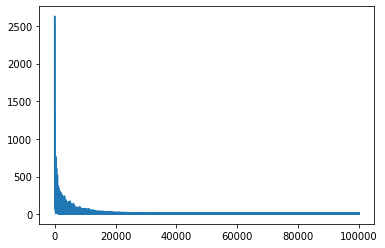

In [ ]:
# SARSA

alpha = 0.01
gamma = 0.9
epsilon = 1
eps_decay_factor = 0.9
eps_min = 0.01
q_table2 = np.zeros([entorno.observation_space.n, entorno.action_space.n])

estado_anterior = None
mostrar_entrenamiento = False
r_mean2 = []
steps_por_episodios2 = []

nro_de_episodios = 100000

def seleccionar_accion(estado):
  if random.uniform(0, 1) < epsilon:
      accion = entorno.action_space.sample()
  else:
      accion = np.argmax(q_table2[estado])
  return accion


for episodio in range(0, nro_de_episodios):
  # Resetear el entorno
  estado = entorno.reset()
  estado_anterior = estado

  # Initialize variables
  recompensa = 0
  r_sum = 0
  r_sums = []
  steps = 0
  terminado = False

  # Tomar el camino aprendido o explorar nuevas acciones basadas en epsilon
  accion = seleccionar_accion(estado)
  
  while not terminado:

      # Tomar la acción   
      siguiente_estado, recompensa, terminado, info = entorno.step(accion) 

      # Tomar el camino aprendido o explorar nuevas acciones basadas en epsilon
      siguiente_accion = seleccionar_accion(siguiente_estado) 

      # Guardar recompensas
      r_sum += recompensa

      steps += 1
      
      # Recalcular
      q_valor = q_table2[estado, accion]
      siguiente_q_valor = q_table2[siguiente_estado, siguiente_accion]
      nuevo_q_valor = (1 - alpha) * q_valor + alpha * (recompensa + gamma * siguiente_q_valor)
      
      # Actualizar Q-table
      q_table2[estado, accion] = nuevo_q_valor
      estado = siguiente_estado
      accion = siguiente_accion

      if(mostrar_entrenamiento):
        time.sleep(0.1)
        clear_output(wait=True)
        print("Episodio: {}".format(episodio + 1))
        entorno.render()
        plt.rcParams["figure.figsize"] = (3,3)
        plt.plot(np.cumsum(vec_recompensa))
        plt.xticks([])
        plt.show()

  epsilon = max(epsilon * eps_decay_factor, eps_min)

  # r_mean2.append(r_sum)
  steps_por_episodios2.append(steps)
  # if episodio%10 == 0 :
  #     r_mean2.append(np.mean(r_sums))

  if (episodio + 1) % 100 == 0:
      clear_output(wait=True)
      print("Episodio: {}".format(episodio + 1))
      entorno.render()


print("**********************************")
print("Entrenamiento Completo!\n")
print("**********************************")

# plot1 = plt.figure(1)
# plt.plot(r_mean2)
plot2 = plt.figure(2)
plt.plot(steps_por_episodios2)
# Tiempo aprox: 115 seg.

In [ ]:
#Test

total_epochs = 0
total_penalties = 0
num_of_episodes = 100

for episode in range(num_of_episodes):
    state = entorno.reset()
    epochs = 0
    penalties = 0
    reward = 0
    
    terminated = False

    # print('Episode: ', episode)
    
    while not terminated:
        action = np.argmax(q_table[state])
        state, reward, terminated, info = entorno.step(action)

        time.sleep(0.5)
        clear_output(wait=True)
        entorno.render()

        if reward == -10:
            penalties += 1

        epochs += 1

    total_penalties += penalties
    total_epochs += epochs

print("**********************************")
print("Results")
print("**********************************")
print("Epochs per episode: {}".format(total_epochs / num_of_episodes))
print("Penalties per episode: {}".format(total_penalties / num_of_episodes))

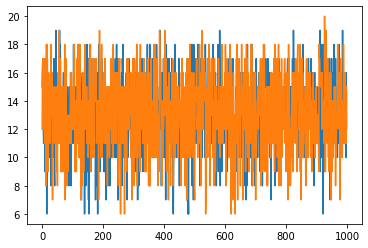

In [ ]:
plt.plot(steps_por_episodios[-1000:-1])
plt.plot(steps_por_episodios2[-1000:-1])

**Referencias**

*   https://gym.openai.com/docs/ 
*   https://rubikscode.net/2019/06/24/introduction-to-q-learning-with-python-and-open-ai-gym/
*   https://www.learndatasci.com/tutorials/reinforcement-q-learning-scratch-python-openai-gym/
*   https://stackoverflow.com/questions/50107530/how-to-render-openai-gym-in-google-colab
*   https://colab.research.google.com/drive/12osEZByXOlGy8J-MSpkl3faObhzPGIrB#scrollTo=tKA52SBe6JdJ 